In [1]:
import os
import time
import platform
from shutil import rmtree
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as image
import seaborn as sns

import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset, TensorDataset, random_split

import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.datasets import ImageFolder
from torchvision.utils import make_grid

# 1. 운영체제별 한글 폰트 설정
if platform.system() == 'Windows':
    plt.rc('font', family='Malgun Gothic')
elif platform.system() == 'Darwin':  # Mac OS
    plt.rc('font', family='AppleGothic')
else:  # Linux (Colab 등)
    plt.rc('font', family='NanumBarunGothic')

# 2. 마이너스 기호(-) 깨짐 방지
plt.rcParams['axes.unicode_minus'] = False

# 오류 발생시
# sklearn.set_config(display="text")

In [2]:
train_transform = transforms.Compose([
    transforms.Resize((64, 64)), # 크기를 변경하는 것부터 시작
    transforms.Grayscale(1), # 흑백
    transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

test_transform = transforms.Compose([
    transforms.Resize((64, 64)), # 크기를 변경하는 것부터 시작
    transforms.Grayscale(1), # 흑백
    transforms.RandomInvert(1),
    transforms.ToTensor(),
    transforms.Normalize(0.5, 0.5),
])

In [3]:
base_path = r"/Users/hyusoohi5/kdt_0900_khs/ml/resource/"
train_path = os.path.join(base_path, "shape", "train")
test_path = os.path.join(base_path, "shape", "test")

In [4]:
train_dataset = ImageFolder(train_path, transform=train_transform)
test_dataset = ImageFolder(test_path, transform=test_transform)

print(len(train_dataset), len(test_dataset))

240 60


In [5]:
class_dict = dict(enumerate(train_dataset.classes))
class_dict

{0: 'cir', 1: 'tri', 2: 'x'}

## CNN을 활용해서 도형 분류하기 실습

In [6]:
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.mps.is_available():
    device = torch.device("mps")
elif torch.xpu.is_available():
    device = torch.device("xpu")
else:
    device = torch.device("cpu")

print(f"현재 선택된 장치: {device}")

현재 선택된 장치: mps


In [7]:
train_dataloader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_dataloader = DataLoader(test_dataset, batch_size=64, shuffle=False)

In [8]:
imgs, labels = next(iter(train_dataloader))

## CNN 모델 준비

In [11]:
class ConvNeuralNetwork(nn.Module):
    def __init__(self):
        super(ConvNeuralNetwork, self).__init__()
        self.flatten = nn.Flatten()
        self.classifier = nn.Sequential(
            nn.Conv2d(1, 28, kernel_size=3, padding="same"), # 64, 64
            nn.ReLU(), # 활성화 함수(선형 -> 비선형)
            nn.Conv2d(28, 28, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 32, 32
            nn.Dropout(0.25),
            
            nn.Conv2d(28, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.Conv2d(56, 56, kernel_size=3, padding="same"),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2), # 16, 16
            nn.Dropout(0.25)
        )
        self.linear = nn.Linear(56 * 16 * 16, 10)
    
    def forward(self, x):
        x = self.classifier(x)
        x = self.flatten(x)
        x = self.linear(x)
        return x

In [12]:
model = ConvNeuralNetwork().to(device)

In [14]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001) # 가중치의 폭주를 막기 위함

In [15]:
def train_one_epoch(model, dataloader, criterion, optimizer, device, log_step=20):
    model.train()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    for i, (imgs, labels) in enumerate(dataloader, 1):
        imgs, labels = imgs.to(device), labels.to(device)

        # 초기화
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = imgs.size(0)
        running_loss += loss.item() * batch_size
        _, preds = outputs.max(1)
        running_corrects += (preds == labels).sum().item()
        total += batch_size

        if log_step and i % log_step == 0:
            batch_acc = (preds == labels).float().mean().item()
            print(f"[Train] batch {i}/{len(dataloader)} | Loss: {loss:.4f} | Accuracy: {batch_acc:.2f}")

    return running_loss / total, running_corrects / total

In [16]:
def evaluate(model, dataloader, criterion, device):
    model.eval()
    total = 0
    running_loss = 0.0
    running_corrects = 0

    with torch.no_grad():
        for i, (imgs, labels) in enumerate(dataloader, 1):
            imgs, labels = imgs.to(device), labels.to(device)
    
            # 초기화
            outputs = model(imgs)
            loss = criterion(outputs, labels)
    
            batch_size = imgs.size(0)
            running_loss += loss.item() * batch_size
            _, preds = outputs.max(1)
            running_corrects += (preds == labels).sum().item()
            total += batch_size

    return running_loss / total, running_corrects / total

In [17]:
epochs = 30

for i in range(epochs):
    # 학습
    train_loss, train_acc = train_one_epoch(
        model=model,
        dataloader=train_dataloader,
        criterion=criterion,
        optimizer=optimizer,
        device=device
    )

    # 평가
    test_loss, test_acc = evaluate(
        model=model,
        dataloader=test_dataloader,
        criterion=criterion,
        device=device
    )

    print(f"Epoch: {i}/{epochs}")
    print(f"[Train] Loss: {train_loss:.4f} | Accuracy: {train_acc * 100:.2f}")
    print(f"[Test] Loss: {test_loss:.4f} | Accuracy: {test_acc * 100:.2f}")

Epoch: 0/30
[Train] Loss: 1.6114 | Accuracy: 25.42
[Test] Loss: 1.2771 | Accuracy: 33.33
Epoch: 1/30
[Train] Loss: 1.1911 | Accuracy: 42.50
[Test] Loss: 1.0570 | Accuracy: 33.33
Epoch: 2/30
[Train] Loss: 1.0618 | Accuracy: 37.08
[Test] Loss: 0.8984 | Accuracy: 66.67
Epoch: 3/30
[Train] Loss: 0.7792 | Accuracy: 67.50
[Test] Loss: 0.6119 | Accuracy: 66.67
Epoch: 4/30
[Train] Loss: 0.5550 | Accuracy: 62.92
[Test] Loss: 0.4794 | Accuracy: 66.67
Epoch: 5/30
[Train] Loss: 0.4338 | Accuracy: 71.67
[Test] Loss: 0.5060 | Accuracy: 68.33
Epoch: 6/30
[Train] Loss: 0.3802 | Accuracy: 81.25
[Test] Loss: 0.4907 | Accuracy: 71.67
Epoch: 7/30
[Train] Loss: 0.2899 | Accuracy: 86.67
[Test] Loss: 0.4645 | Accuracy: 75.00
Epoch: 8/30
[Train] Loss: 0.2208 | Accuracy: 90.83
[Test] Loss: 0.4546 | Accuracy: 73.33
Epoch: 9/30
[Train] Loss: 0.1804 | Accuracy: 91.67
[Test] Loss: 0.4945 | Accuracy: 78.33
Epoch: 10/30
[Train] Loss: 0.1340 | Accuracy: 95.00
[Test] Loss: 0.4897 | Accuracy: 76.67
Epoch: 11/30
[Train]

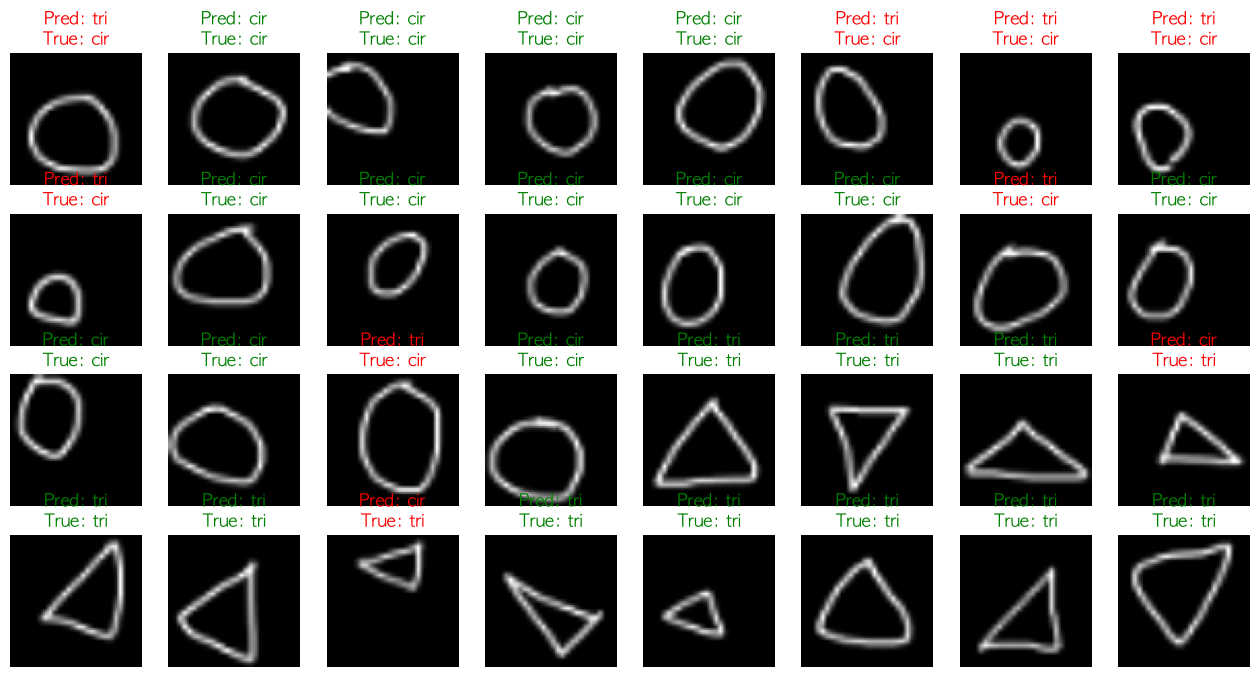

In [21]:
model.eval()

imgs, labels = next(iter(test_dataloader))
imgs_dev = imgs.to(device)

with torch.no_grad():
    outputs = model(imgs_dev)
    _, preds = outputs.max(1)

img_list_cpu = imgs.cpu()
y_pred_list_cpu = preds.cpu()
y_true_list_cpu = labels.cpu()

# 시각화
fig, axes = plt.subplots(4, 8, figsize=(16, 8))

for ax, img, y_pred, y_true in zip(axes.flatten(), img_list_cpu, y_pred_list_cpu, y_true_list_cpu):
    ax.imshow(img.squeeze(), cmap="gray")
    # ax.imshow(img.permute(1, 2, 0), cmap="gray")

    pred_label = class_dict[y_pred.item()]
    true_label = class_dict[y_true.item()]
    color = "green" if pred_label == true_label else "red"
    ax.axis("off")
    ax.set_title(f"Pred: {pred_label}\nTrue: {true_label}", color=color)

plt.show()

## 그림판에 도형을 그려 비교해보기

In [18]:
shape_path = r"/Users/hyusoohi5/kdt_0900_khs/ml/resource/복잡한 도형.png"
shape_path

'/Users/hyusoohi5/kdt_0900_khs/ml/resource/복잡한 도형.png'

In [19]:
from PIL import Image

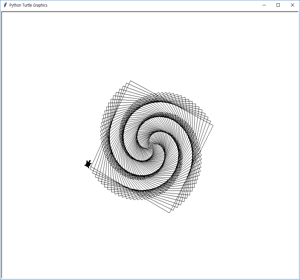

In [20]:
image = Image.open(shape_path).convert("RGB")
image = image.resize((300, 280))

image

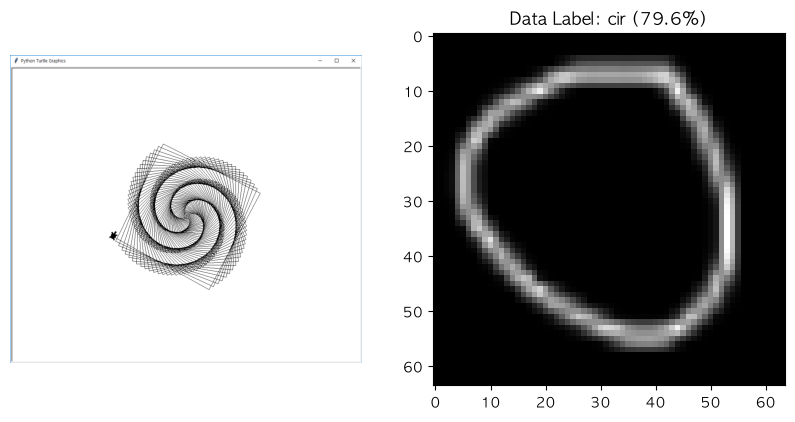

In [22]:
shape = Image.open(shape_path).convert("RGB")
input_tensor = test_transform(shape)

# 1채널 그대로 사용
input_tensor_dev = input_tensor.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():
    outputs = model(input_tensor_dev)
    probs = F.softmax(outputs, dim=1)[0]

    pred_idx = torch.argmax(probs).item()
    pred_class = class_dict[pred_idx]
    confidence = probs[pred_idx].item() * 100

dataset_sample_img = None

for sample_img, sample_label in train_dataset:
    if sample_label == pred_idx:
        dataset_sample_img = sample_img
        break

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# 0 복잡한 도형
axes[0].imshow(shape)
axes[0].axis("off")

# 예측 클래스와 같은 데이터 예시
if dataset_sample_img is not None:
    axes[1].imshow(
        dataset_sample_img.squeeze(0).numpy(),
        cmap="gray"
    )
    axes[1].set_title(
        f"Data Label: {pred_class} ({confidence:.1f}%)"
    )
else:
    axes[1].set_title("No matching sample found")